# Rysk V12: 10 October 2025 to 09 October 2026
Expiry cohort on HyperEVM; both 08:00 UTC boundaries included.
Start from a clean kernel. This notebook verifies input hashes, then regenerates the tables and charts.
Option result is writer premium minus oracle-derived payoff. The combined scenario adds a proxy for the change in call collateral value while each option was open. Redemption transfers and wallet-wide returns are outside this calculation.

In [1]:
import csv, gzip, hashlib, json, sys, tempfile
from pathlib import Path

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "option_intel").is_dir())
sys.path.insert(0, str(ROOT))
BUNDLE = next(
    p
    for p in (ROOT / "research/rysk/rysk-year", ROOT / "articles/rysk/rysk-year")
    if (p / "data/CHECKSUMS.txt").is_file()
)
SNAPSHOT = BUNDLE / "data"
scratch = tempfile.TemporaryDirectory(prefix="rysk-year-")
WORK = Path(scratch.name)
expected = {
    line.split()[1]: line.split()[0] for line in (SNAPSHOT / "CHECKSUMS.txt").read_text().splitlines()
}
for name, sha in expected.items():
    payload = gzip.decompress((SNAPSHOT / (name + ".gz")).read_bytes())
    assert hashlib.sha256(payload).hexdigest() == sha, name
    (WORK / name).write_bytes(payload)
print(f"Verified {len(expected)} input files")
config = json.loads((WORK / "data__cache__rysk-year-provenance.json").read_text())
for name, sha in config["input_sha256"].items():
    assert hashlib.sha256((WORK / name).read_bytes()).hexdigest() == sha, name
for name, sha in config["code_sha256"].items():
    assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == sha, (
        f"Code differs from snapshot: {name}"
    )
print(json.dumps({k: v for k, v in config.items() if k != "code_sha256"}, indent=2))


Verified 11 input files
{
  "asof": "2026-10-09T17:29:23.283222+00:00",
  "chain": "hyperevm",
  "collateral_receipt_evidence": {
    "chain": "hyperevm",
    "collateral_token": "0x94e8396e0869c9f2200760af0621afd240e1cf38",
    "decimals": 18,
    "rows": 220,
    "selection": "stHYPE-labelled source rows plus five wstHYPE rows in the expiry cohort",
    "source": "eth_getTransactionReceipt"
  },
  "collateral_transfer_outlier": {
    "block": 22529167,
    "execution_evidence": "Two independent debug_traceTransaction providers show proxy DELEGATECALL to the historical implementation; bundled transaction payload and receipt are verified offline.",
    "historical_implementation": "0xfad2adf5aca6043cc00def6e74ef901725d14632",
    "minted_call_contracts": 50,
    "signed_collateral_khype": 5000,
    "treatment": "Retain signed 5000-unit position collateral in underlying-price proxy; report 50-unit counterfactual",
    "tx_hash": "0xf88a8ca30a002e4d59ceaf0f6bab9a90db035edf240cada894f3361

## Sources and reconstruction
The collector discovers option-token series from Rysk factory logs, probes each series contract for strike, expiry, option side and asset addresses, then scans their Transfer logs in bounded block ranges. For each candidate transaction it reads the receipt: a mint identifies a sale, token transfers identify the writer, gross stablecoin paid from the maker-side contract, other stablecoin outflows and the writer-to-pool collateral transfer. The sales ledger contains primary writes only: no-mint transactions and ambiguous multi-series mints are excluded, and accepted rows are deduplicated by transaction hash. The provenance records incremental scan boundaries, the terminal block and hash, and an overlapping receipt replay range. It is not a full receipt archive or fresh replay of the older ledger.
The oracle snapshot contains ExpiryPriceUpdated events keyed by chain, underlying address and 08:00 UTC expiry. Hyperliquid hourly/four-hourly candle closes and Binance minute observations supply writing-price proxies. All fetched observations used here are frozen in the input bundle.
The pinned collateral receipts supply transfer addresses, raw amounts and log indices for the receipt-backed rows. A separate full-cohort receipt scan splits maker-side payments by recipient; receipts for every transfer to the less-used address are pinned. RyskHype currently labels the addresses feeRecipient and gasFeeRecipient in its read-as-proxy getters. Those getters were checked on 2026-09-27; historical recipient settings were not reconstructed.

## Compute the expiry cohort
Reconstruction uses a temporary copy of the inputs and makes no network requests. Missing spot hours or oracle prices, duplicate sales, and dropped eligible rows stop the calculation.

In [2]:
import socket
from unittest.mock import patch
from option_intel import rysk_year

with patch.object(socket.socket, "connect", side_effect=RuntimeError("Offline notebook")):
    rows, published = rysk_year.calculate(WORK, config)
(BUNDLE / "figures.json").write_text(json.dumps(published, indent=2) + "\n")
rysk_year.export_tables(rows, published, (BUNDLE / "tables"))
print(json.dumps(published["coverage"], indent=2))
print(published["window"])


{
  "eligible_sales": 40067,
  "reconstructed": 40067,
  "oracle_priced": 40067,
  "spot_fallback": 0,
  "near_strike_hourly": 3873,
  "near_strike_unrefined": 60
}
{'start': '2025-10-10T08:00:00+00:00', 'end': '2026-10-09T08:00:00+00:00', 'chain': 'hyperevm', 'days': 364}


## Audit the collected rows against the calculated cohort
This cell checks every eligible source row against the reconstructed result. It resolves each settlement price by the exact underlying address on that row's option token, independently of the library's ticker lookup. The payment check starts with the gross stablecoin transfers recorded in the source ledger and confirms that the writer premium is gross minus all non-writer outflows. The ledger labels those outflows `fee`, although they include transfers to the address now configured as gasFeeRecipient. The pinned payment audit identifies the recipients and checks each transfer to that address against its receipt.

In [3]:
import math
from collections import Counter
from datetime import datetime

raw_sales = []
for filename in ("data__onchain__rysk__sales.csv", "data__onchain__rysk-eth__sales.csv"):
    with gzip.open(SNAPSHOT / (filename + ".gz"), "rt") as stream:
        raw_sales.extend(csv.DictReader(stream))
start = datetime.fromisoformat(config["window"]["start"])
end = datetime.fromisoformat(config["window"]["end"])
source = [
    r
    for r in raw_sales
    if r["chain"] == config["chain"]
    and start.date() <= datetime.fromisoformat(r["expiry"]).date() <= end.date()
]
source_by_tx = {r["tx_hash"]: r for r in source}
result_by_tx = {r.tx_hash: r for r in rows}
exposure_anomalies = {r["tx_hash"]: r for r in published["collateral_exposure_anomalies"]}
assert len(source) == len(source_by_tx) == len(result_by_tx) == len(rows)
assert source_by_tx.keys() == result_by_tx.keys()
tokens = {}
for filename in ("data__cache__otokens-rysk.json", "data__cache__otokens-rysk-eth.json"):
    tokens.update(json.loads((WORK / filename).read_text()))
with (WORK / "data__cache__oracle-prices.csv").open() as stream:
    exact_oracle = {
        (chain, address.lower(), int(expiry)): float(price)
        for chain, address, expiry, price in csv.reader(stream)
    }
for tx, sale in source_by_tx.items():
    result = result_by_tx[tx]
    token = tokens[sale["otoken"]]
    assert token["strike"] == float(sale["strike"]) == result.strike
    assert token["is_put"] == (sale["option_type"] == "P")
    assert token["expiry_ts"] == int(result.expired_at.timestamp())
    assert sale["writer"].lower() == result.writer.lower()
    assert sale["underlying"] == result.underlying
    assert sale["option_type"] == result.option_type.value
    assert math.isclose(float(sale["contracts"]), result.contracts, abs_tol=1e-8)
    assert math.isclose(float(sale["premium"]) - float(sale["fee"]), result.premium, abs_tol=1e-7)
    assert math.isclose(float(sale["fee"]), result.fee, abs_tol=1e-7)
    if tx in exposure_anomalies:
        anomaly = exposure_anomalies[tx]
        assert (
            float(sale["collateral_amount"]) == anomaly["writer_to_pool_transfer"] == result.collateral_amount
        )
    elif sale["collateral_symbol"] != "stHYPE":
        assert math.isclose(float(sale["collateral_amount"]), result.collateral_amount, abs_tol=1e-8)
    key = (sale["chain"], token["underlying_address"].lower(), int(result.expired_at.timestamp()))
    assert math.isclose(exact_oracle[key], result.spot_at_expiry, abs_tol=1e-8)
gross = math.fsum(float(r["premium"]) for r in source)
non_writer = math.fsum(float(r["fee"]) for r in source)
net = math.fsum(r.premium for r in rows)
assert math.isclose(gross - non_writer, net, abs_tol=1e-6)
assert math.isclose(non_writer, published["fee"]["total"], abs_tol=1e-6)
assert math.isclose(
    published["fee"]["rysk_fee_recipient_total"] + published["fee"]["gas_fee_recipient_total"],
    non_writer,
    abs_tol=1e-6,
)
assert sum(float(r["fee"]) > 0 for r in source) == published["fee"]["sales_charged"]
assert (
    sum(r["collateral_symbol"] in ("stHYPE", "wstHYPE") for r in source)
    == published["accounting_audit"]["receipt_backed_collateral_rows"]
)
assert len(exposure_anomalies) == published["accounting_audit"]["oversized_transfer_rows"]
print("Source rows by chain:", dict(Counter(r["chain"] for r in raw_sales)))
print(
    "Cohort rows / unique receipts / exact-address oracle matches:",
    len(source),
    len(source_by_tx),
    len(result_by_tx),
)
print("Written before expiry-window start:", sum(r.written_at < start for r in rows))
print("Gross outflow / non-writer outflow / writer premium:", gross, non_writer, net)
print(
    "Current feeRecipient address / current gasFeeRecipient address / transactions:",
    published["fee"]["rysk_fee_recipient_total"],
    published["fee"]["gas_fee_recipient_total"],
    published["fee"]["gas_transactions"],
)
print(
    "Rows with non-writer outflow / without:",
    published["fee"]["sales_charged"],
    published["fee"]["sales_free"],
)
print("Receipt-backed collateral rows:", published["accounting_audit"]["receipt_backed_collateral_rows"])
print("Oversized collateral transfer and 50-unit sensitivity:", exposure_anomalies)


Source rows by chain: {'hyperevm': 42756, 'ethereum': 555}
Cohort rows / unique receipts / exact-address oracle matches: 40067 40067 40067
Written before expiry-window start: 1058
Gross outflow / non-writer outflow / writer premium: 17732797.9932 1872581.799852 15860216.193348
Current feeRecipient address / current gasFeeRecipient address / transactions: 1872560.358196 21.441656 12
Rows with non-writer outflow / without: 38647 1420
Receipt-backed collateral rows: 220
Oversized collateral transfer and 50-unit sensitivity: {'0xf88a8ca30a002e4d59ceaf0f6bab9a90db035edf240cada894f3361d5e882403': {'tx_hash': '0xf88a8ca30a002e4d59ceaf0f6bab9a90db035edf240cada894f3361d5e882403', 'collateral_symbol': 'kHYPE', 'writer_to_pool_transfer': 5000.0, 'call_contracts': 50.0, 'source_proxy_units': 5000.0, 'comparison_units': 50.0, 'source': 'Pinned transaction payload and receipt', 'historical_implementation': '0xfad2adf5aca6043cc00def6e74ef901725d14632', 'interpretation': 'Signed position collateral is

## Measures and independent reconciliation
For each option, payoff = contracts × max(expiry price − strike, 0) for a call; for a put the price difference is reversed. Option P&L = writer premium − payoff.
The combined scenario adds collateral units × (underlying expiry price − underlying writing price) for calls. Stablecoin collateral is held at face value. Each collateral token is treated as one underlying unit: staking exchange rates, PT discounts and wrapper basis are not measured. This is an estimate, not token-specific investment P&L.
Strike distance is K / S at writing − 1; a threshold of ten percent means K > 1.10 × S. The asset breakdown includes every underlying in the cohort.
The wallet mean is the sum divided by the number of addresses. The median is the middle wallet after sorting. Means add across components; medians generally do not.
For rows covered by the included receipt subset, collateral quantities are reconstructed from transfers of the token named by the option contract. Remaining rows use the source ledger collateral quantities. Where a token emits share and balance representations, only the matching token address is included. The pinned receipt evidence and selected log indices are exported in tables/collateral-reconstruction.json.
One kHYPE writer-to-pool transfer is 5,000 units while the same transaction mints a 50-unit call. The historical contract implementation deposits the signed collateralAmount field separately from the minted quantity; the transaction signed 5,000 kHYPE as collateral. The proxy retains those 5,000 units. tables/collateral-exposure-anomalies.json shows a 50-unit counterfactual, not a correction. Neither case measures the kHYPE token exchange rate or exact collateral-token P&L.
A separate decimal-arithmetic calculation derives payoff and aggregates addresses without calling the main P&L functions. Its assertions compare totals, mean, median and positive counts to the canonical results.

In [4]:
audit = published["accounting_audit"]
for basis in ("option_only", "combined_proxy"):
    print(basis, json.dumps(audit[basis], indent=2))
print("Collateral scenario increment:", audit["collateral_proxy_change"])
print("Mean increment:", audit["mean_change"])
print("Wallet sign transitions:", audit["transitions"])
print("Collateral receipt coverage:", audit["receipt_backed_collateral_rows"])
print("Oversized transfer rows:", audit["oversized_transfer_rows"])
for token in audit["by_collateral"]:
    print(token)
print("Largest collateral-scenario contributions:")
for wallet in audit["top_changes"]:
    print(wallet)


option_only {
  "total": -9522204.07180738,
  "mean": -3334.1050671594467,
  "median": 41.753895,
  "positive": 1838,
  "positive_share": 0.6435574229691877
}
combined_proxy {
  "total": 6541154.913997,
  "mean": 2290.3203480381653,
  "median": 59.576531,
  "positive": 1706,
  "positive_share": 0.5973389355742297
}
Collateral scenario increment: 16063358.98580438
Mean increment: 5624.425415197612
Wallet sign transitions: {'False_to_False': 429, 'False_to_True': 589, 'True_to_False': 721, 'True_to_True': 1117}
Collateral receipt coverage: 220
Oversized transfer rows: 1
{'options': 81, 'option_result': 3336.861293, 'collateral_proxy_change': -8240.412117, 'collateral': 'FXRP', 'combined_proxy': -4903.550824}
{'options': 381, 'option_result': -1144613.674608, 'collateral_proxy_change': 2355781.4175635, 'collateral': 'LHYPE', 'combined_proxy': 1211167.7429555}
{'options': 63, 'option_result': 13258.201099, 'collateral_proxy_change': -94716.934835, 'collateral': 'PT-kHYPE-13NOV2025', 'combi

## Published metrics
This cell prints the metrics calculated above and used in the article.

In [5]:
from option_intel.prose import flatten

for name, value in flatten(published).items():
    print(f"{name:<65} {value:,.10g}")


window.days                                                       364
settled                                                           40,067
writers                                                           2,856
calls                                                             18,031
puts                                                              22,036
collateral.at_write                                               605,433,651.4
collateral.at_expiry                                              621,497,010.3
call_totals.asset                                                 16,063,358.99
call_totals.premium                                               6,991,467.722
call_totals.paid                                                  -18,030,666.04
call_totals.net                                                   5,024,160.667
call_totals.retained                                              0.3127714864
call_totals.paid_multiple                                         2.578952912
c

## The three covered-call outcomes
First separate calls in the money at expiry; only then split the worthless calls by the direction of the asset move. This includes calls opened in the money.

In [6]:
for name in ("fell", "under", "through"):
    print(name, published["buckets"][name])


fell {'calls': 8884, 'collateral': 298122272.0065, 'asset': -23214200.87845955, 'premium': 3470500.134922, 'paid': -0.0, 'net': -19743700.74353755}
under {'calls': 4695, 'collateral': 167198987.3705, 'asset': 9542380.304986449, 'premium': 1547467.71388, 'paid': -0.0, 'net': 11089848.01886645}
through {'calls': 4452, 'collateral': 140112391.98125, 'asset': 29735179.559277482, 'premium': 1973499.872994, 'paid': -18030666.04052748, 'net': 13678013.391743999}


## Generate charts
Draw PNG and SVG files from the rows and metrics calculated above.

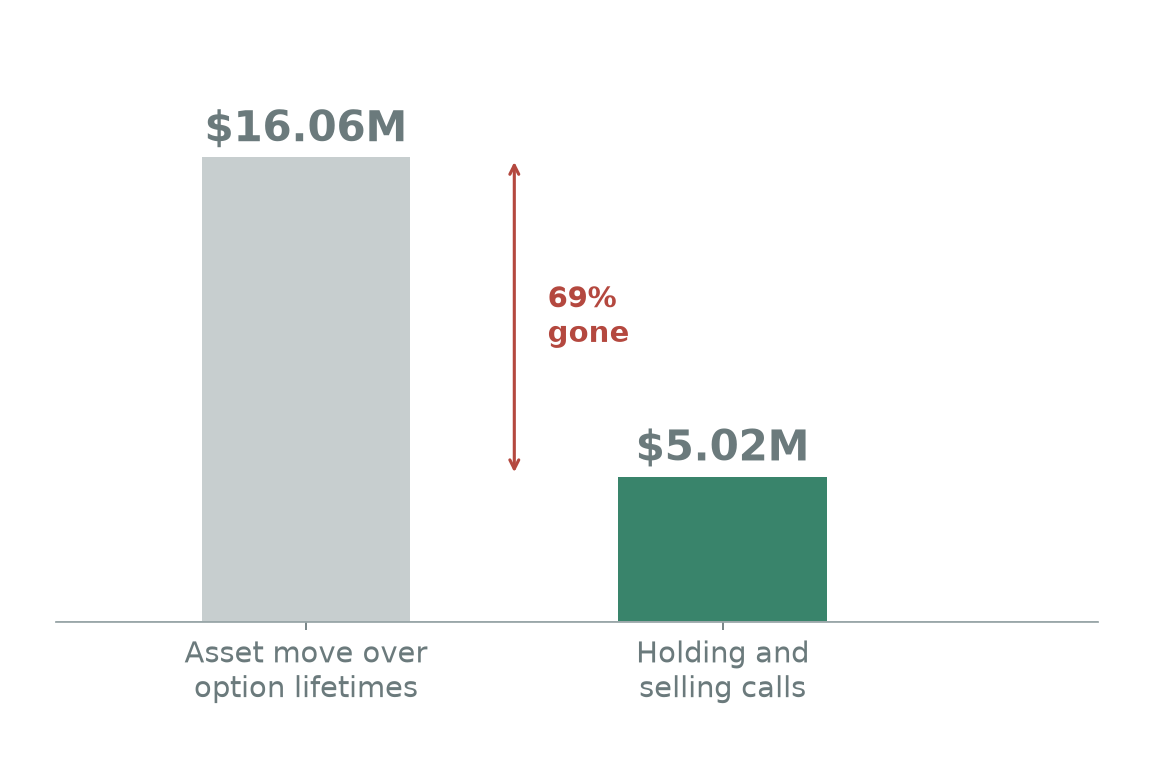

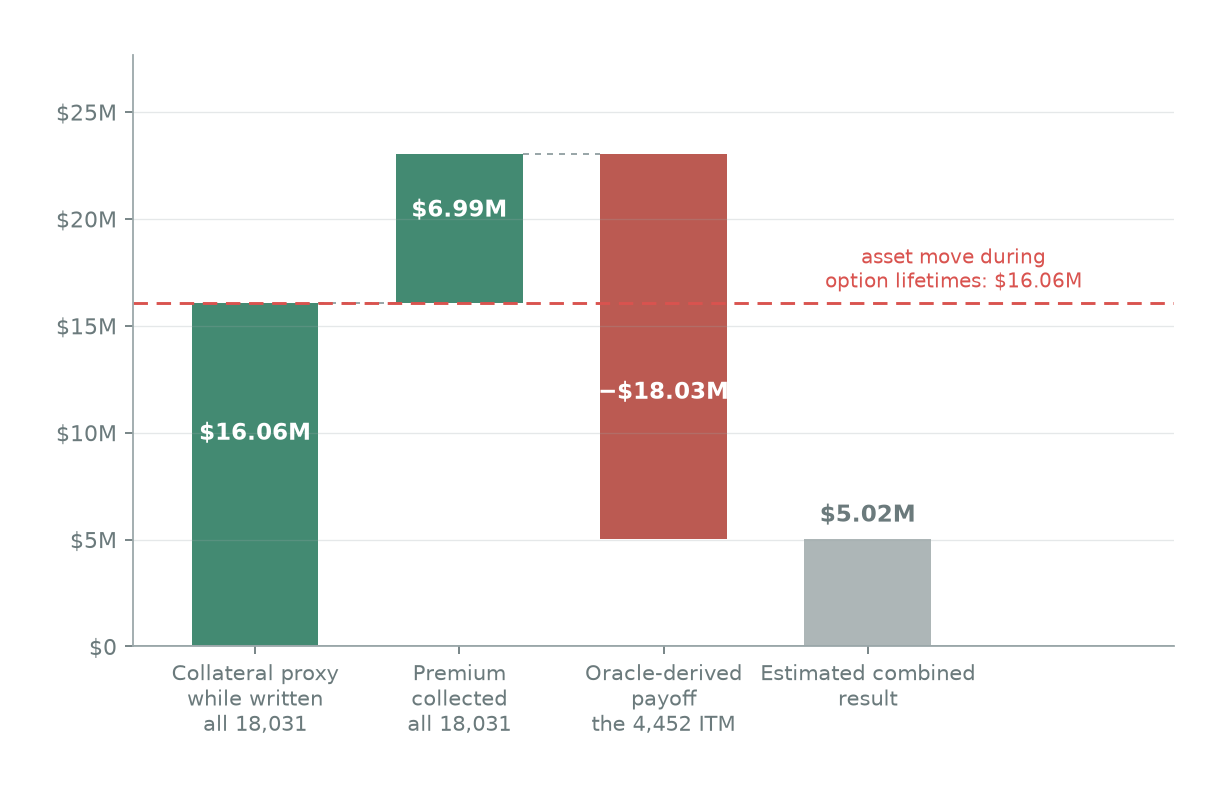

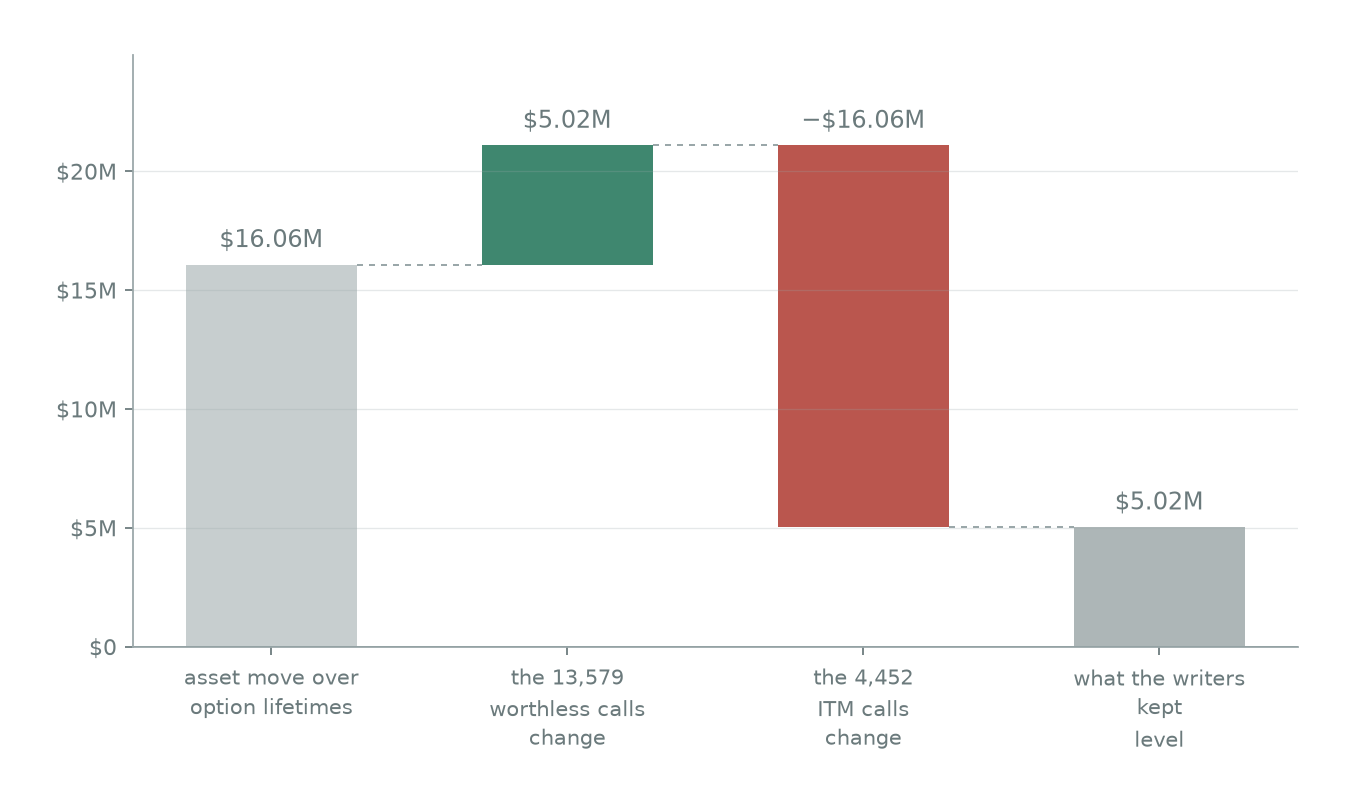

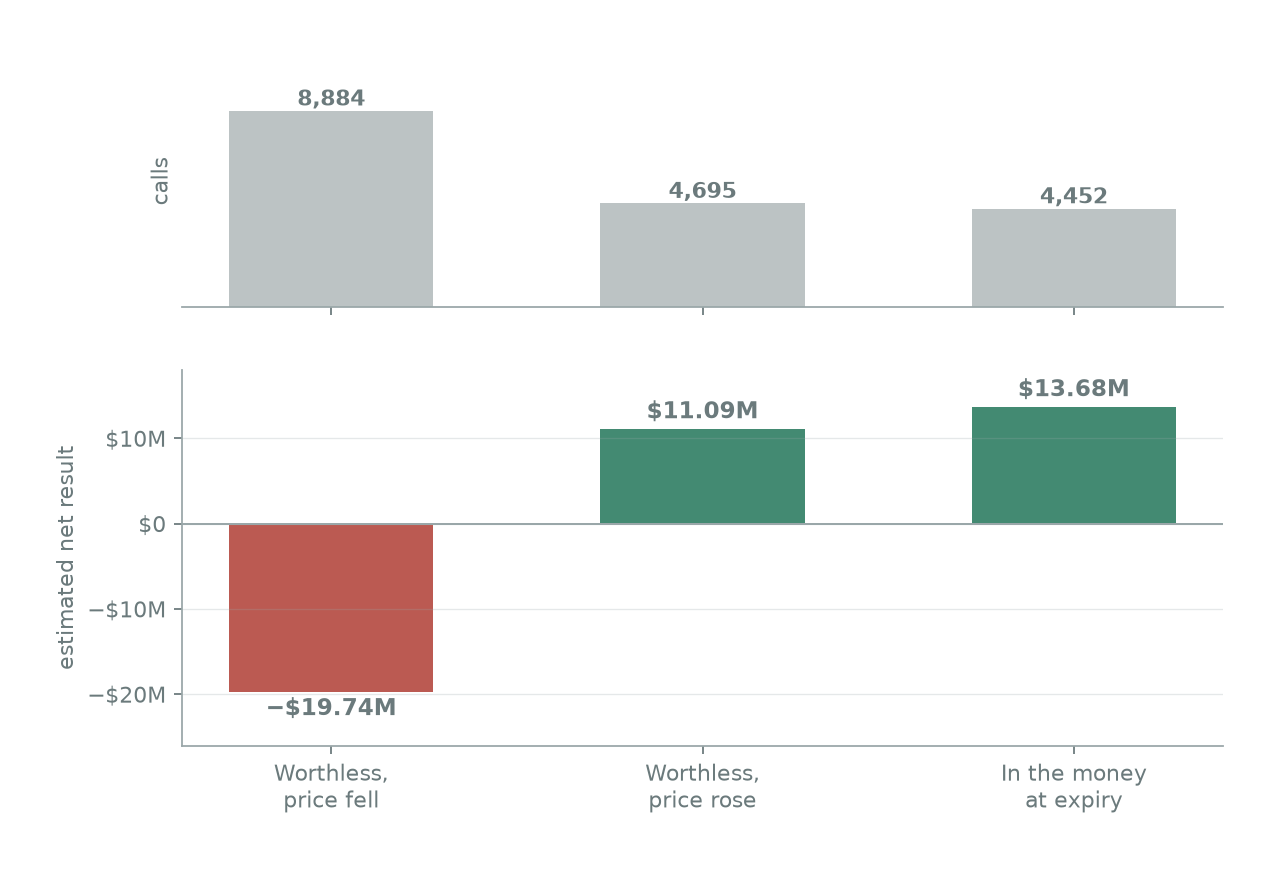

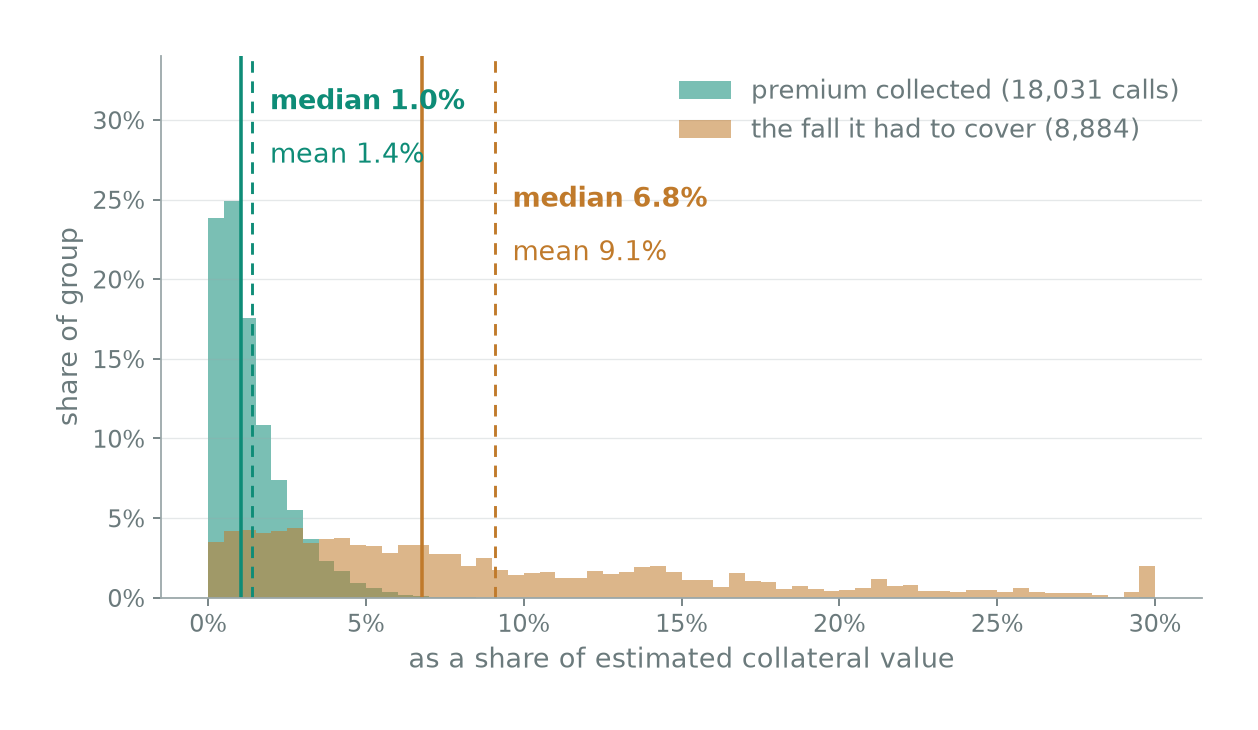

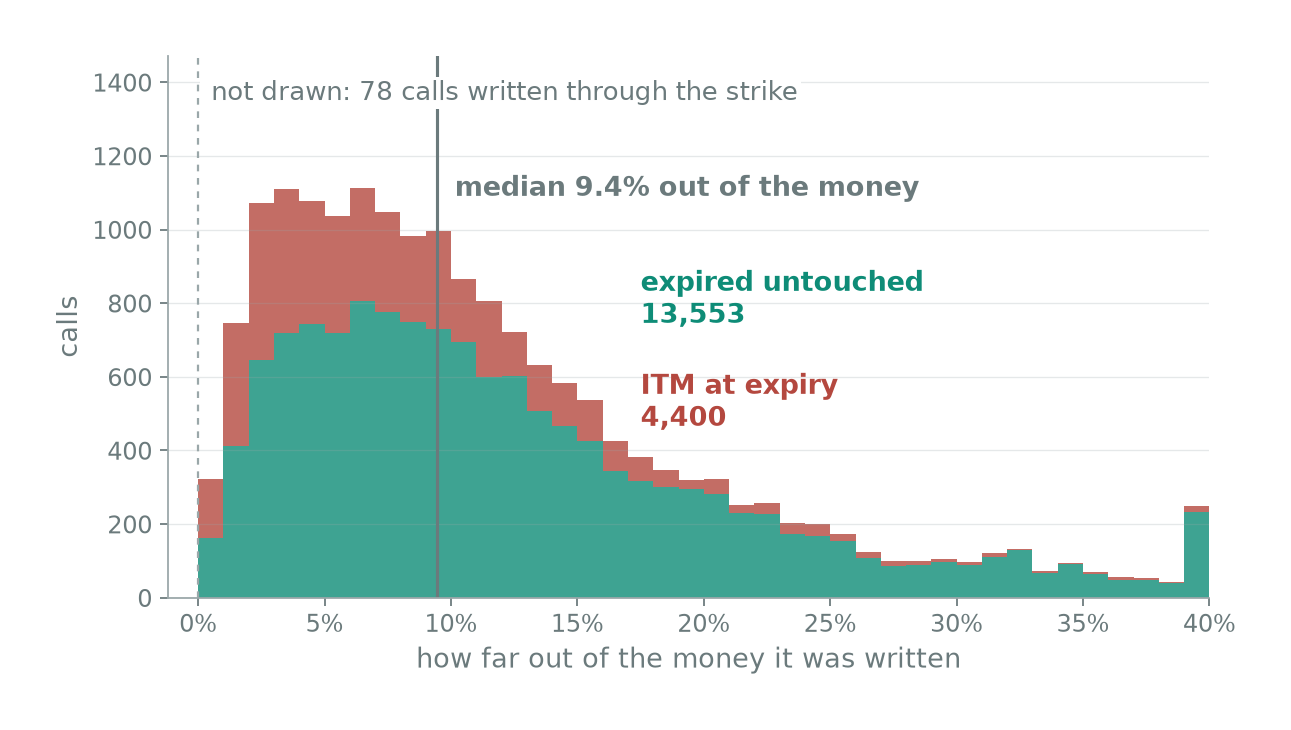

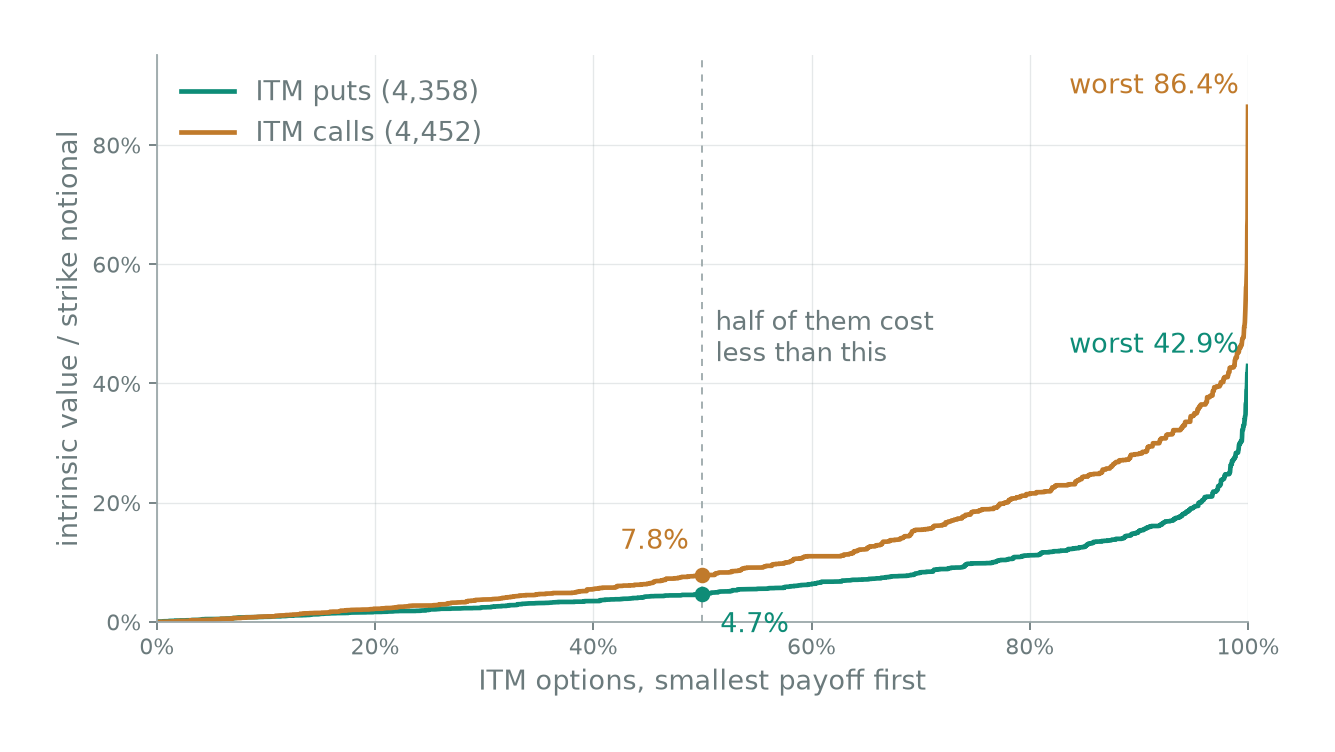

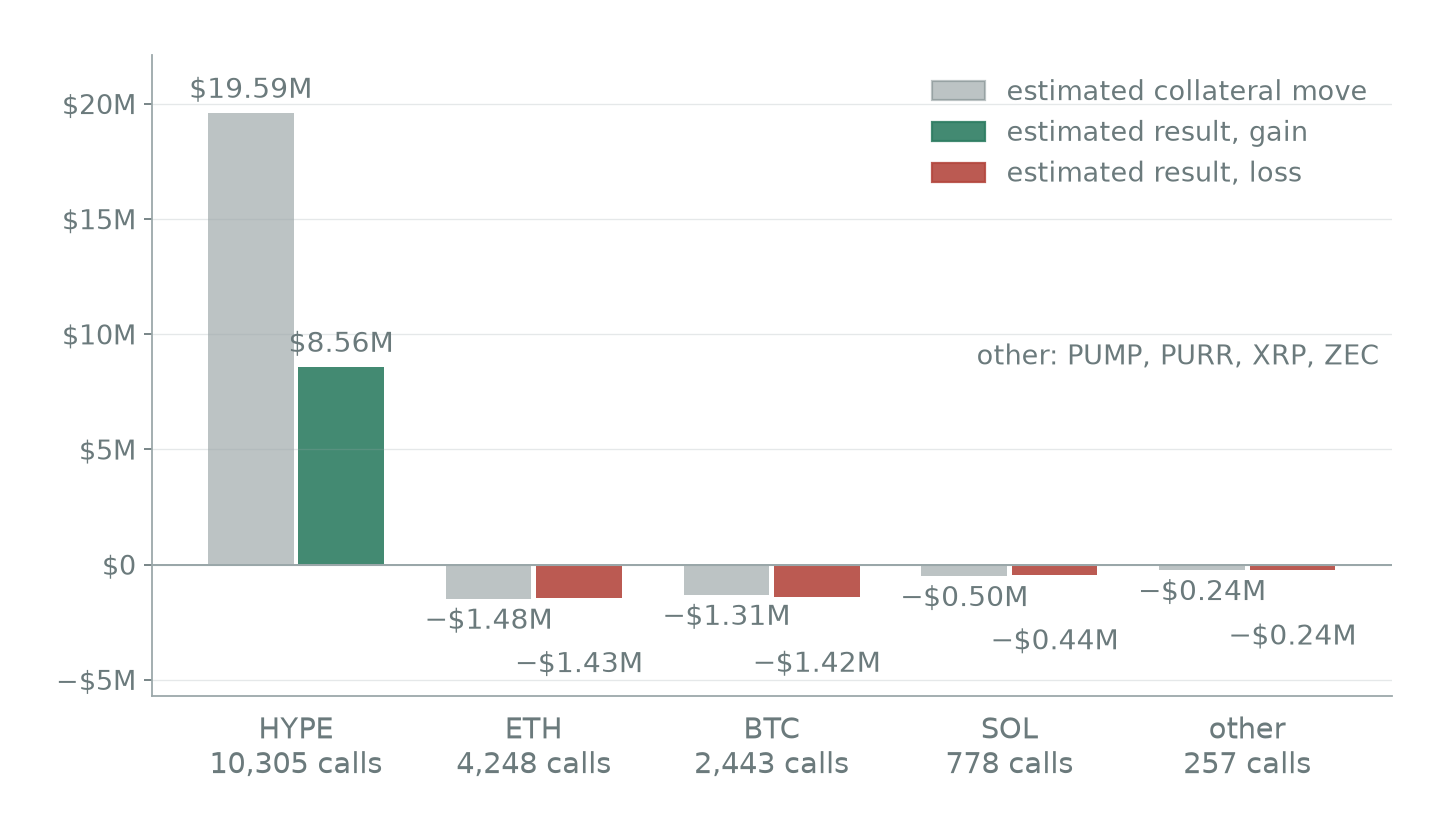

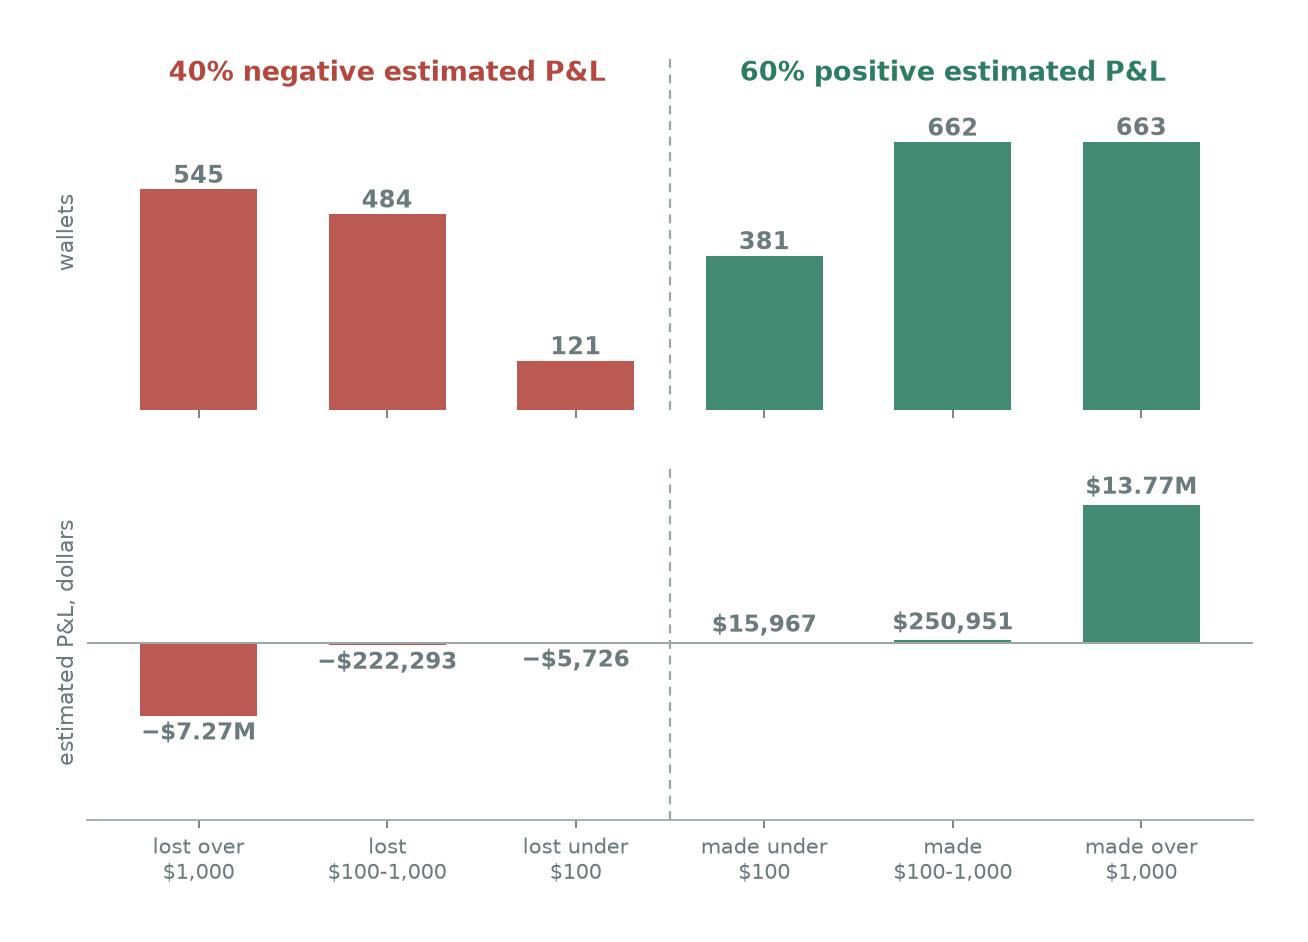

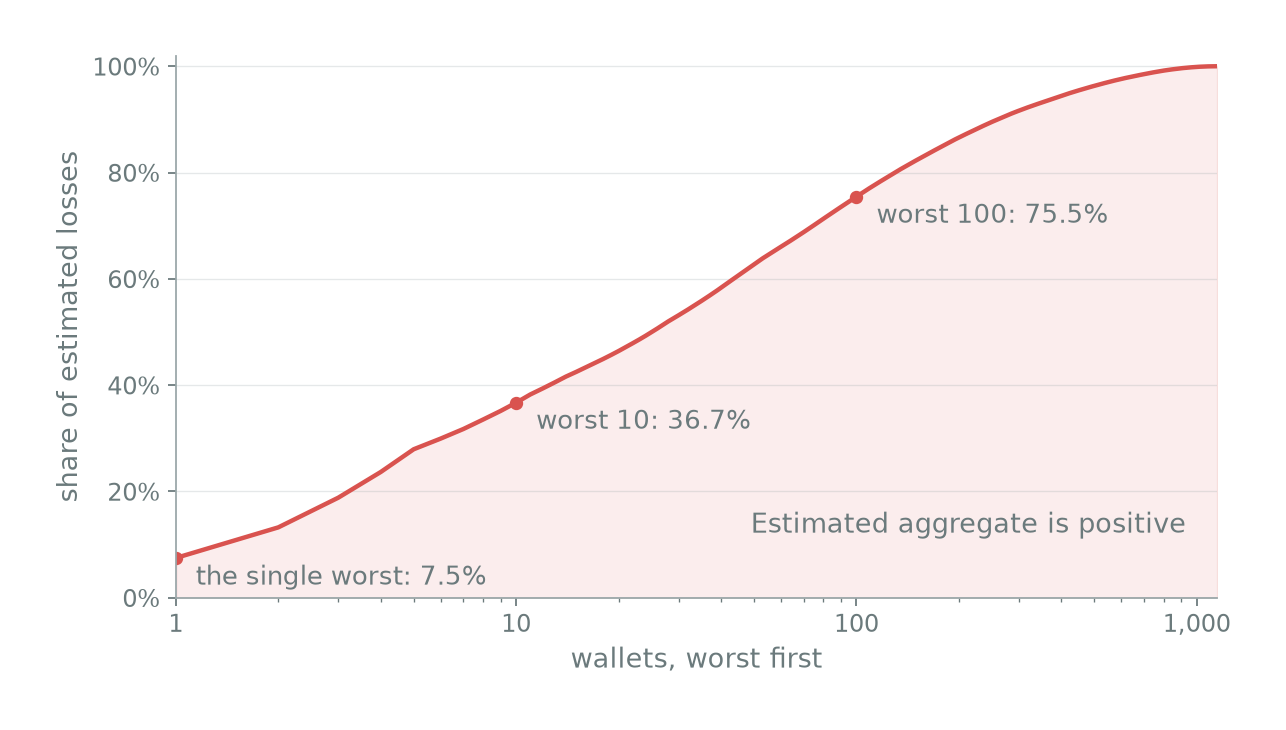

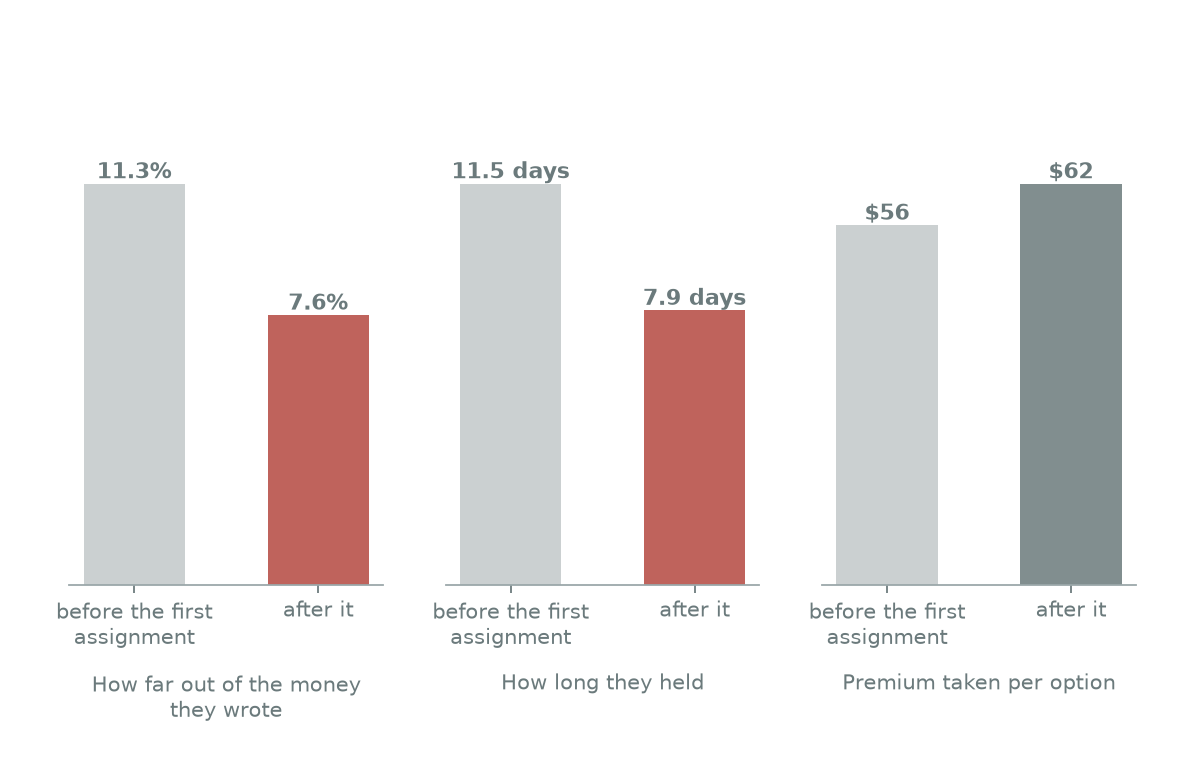

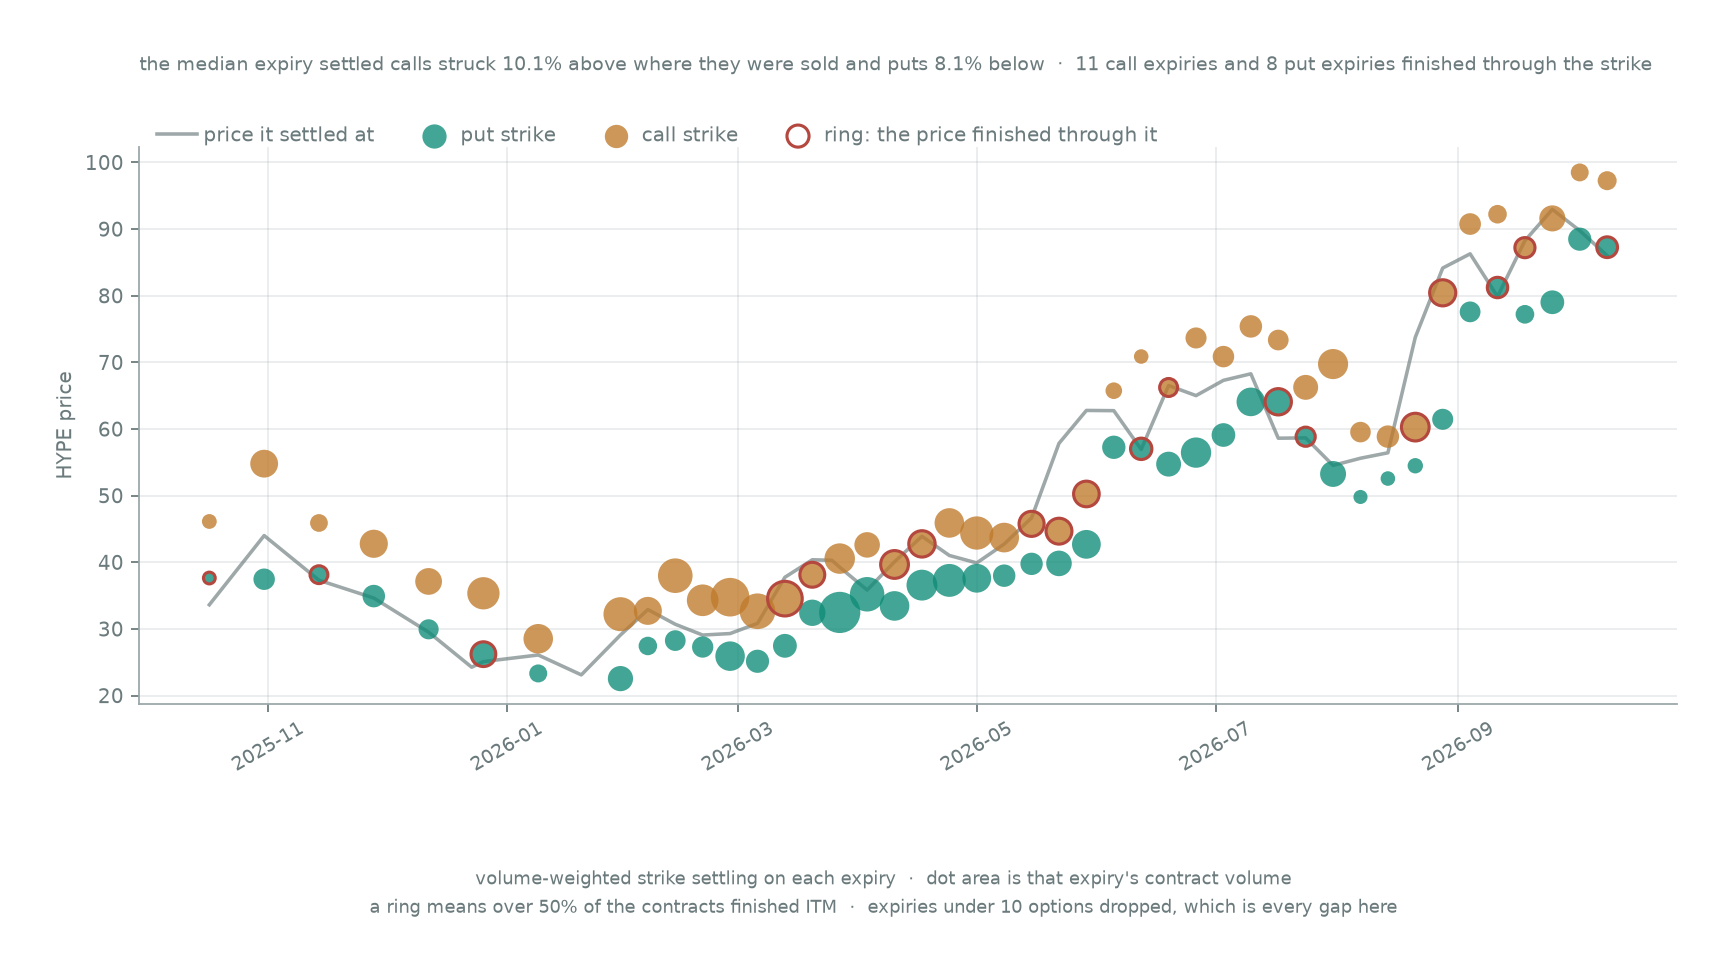

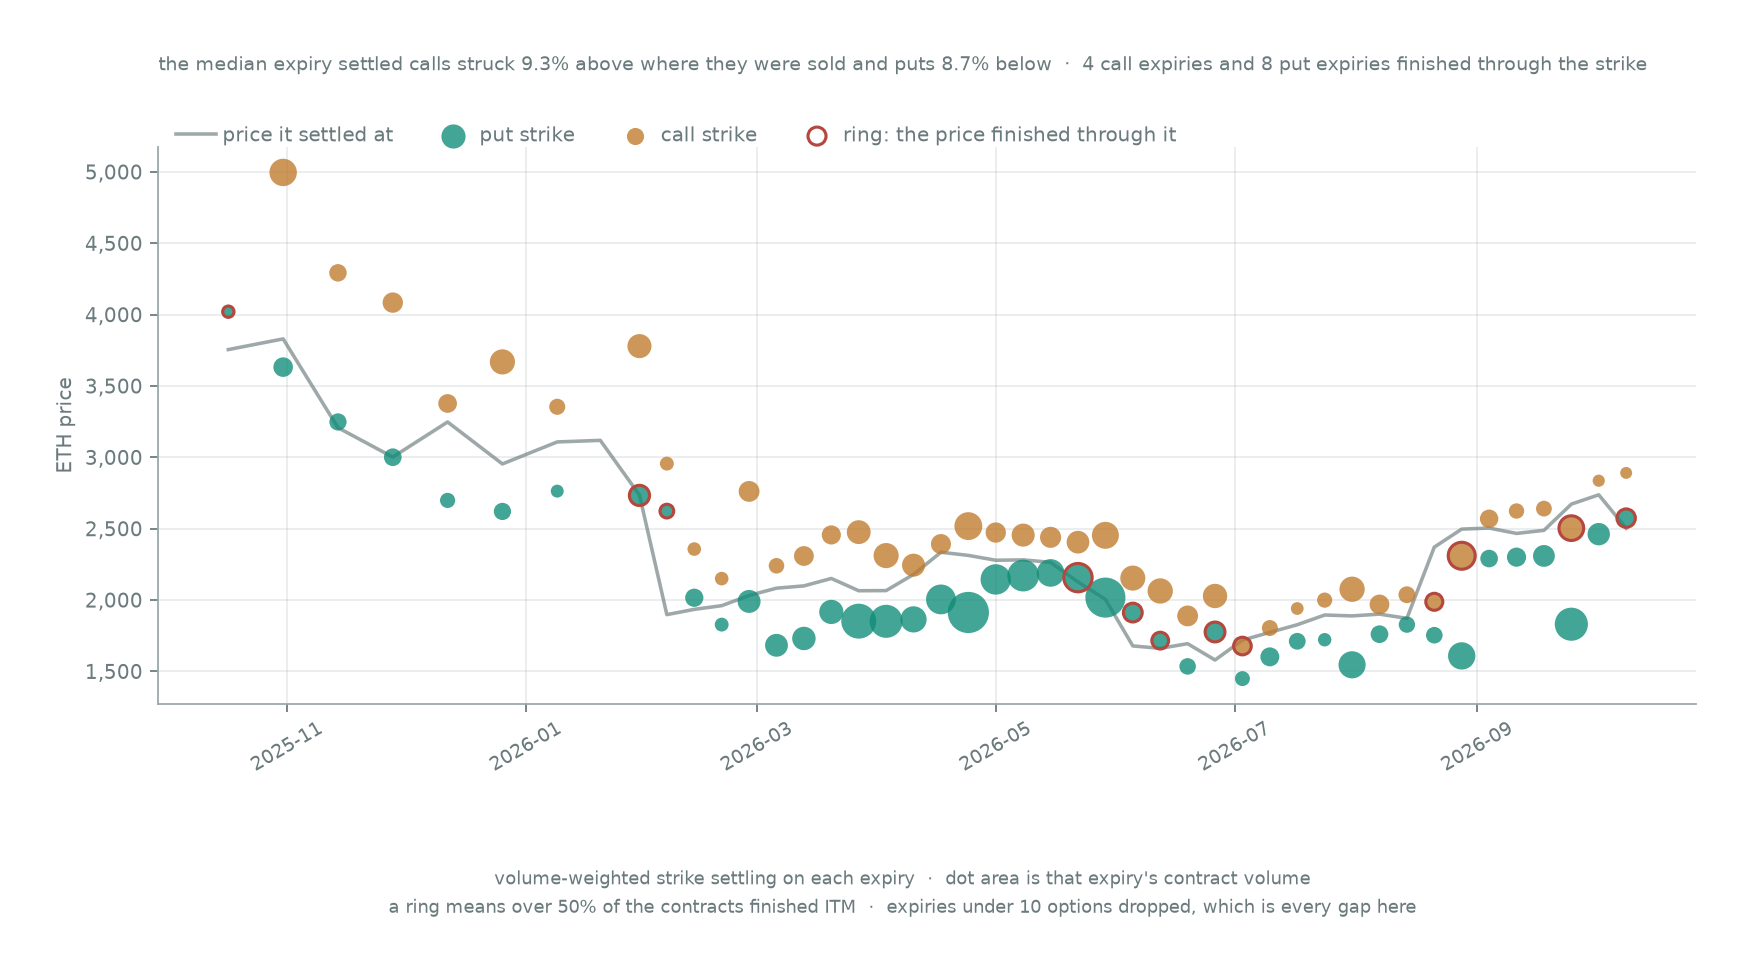

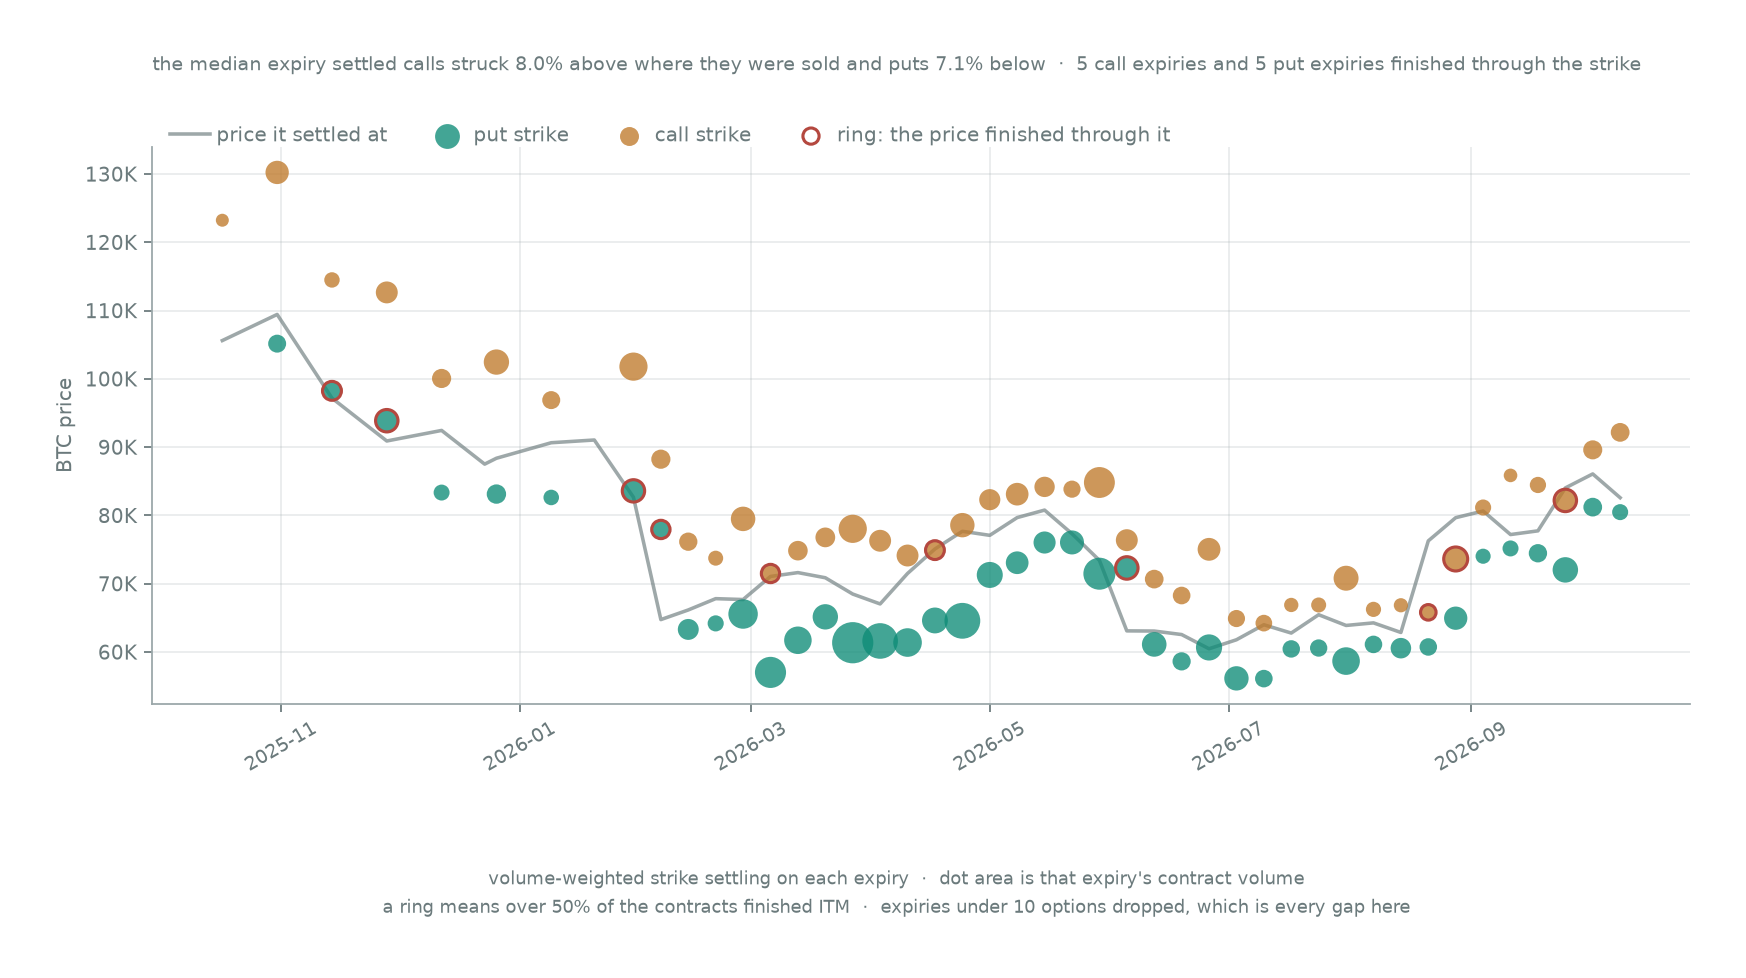

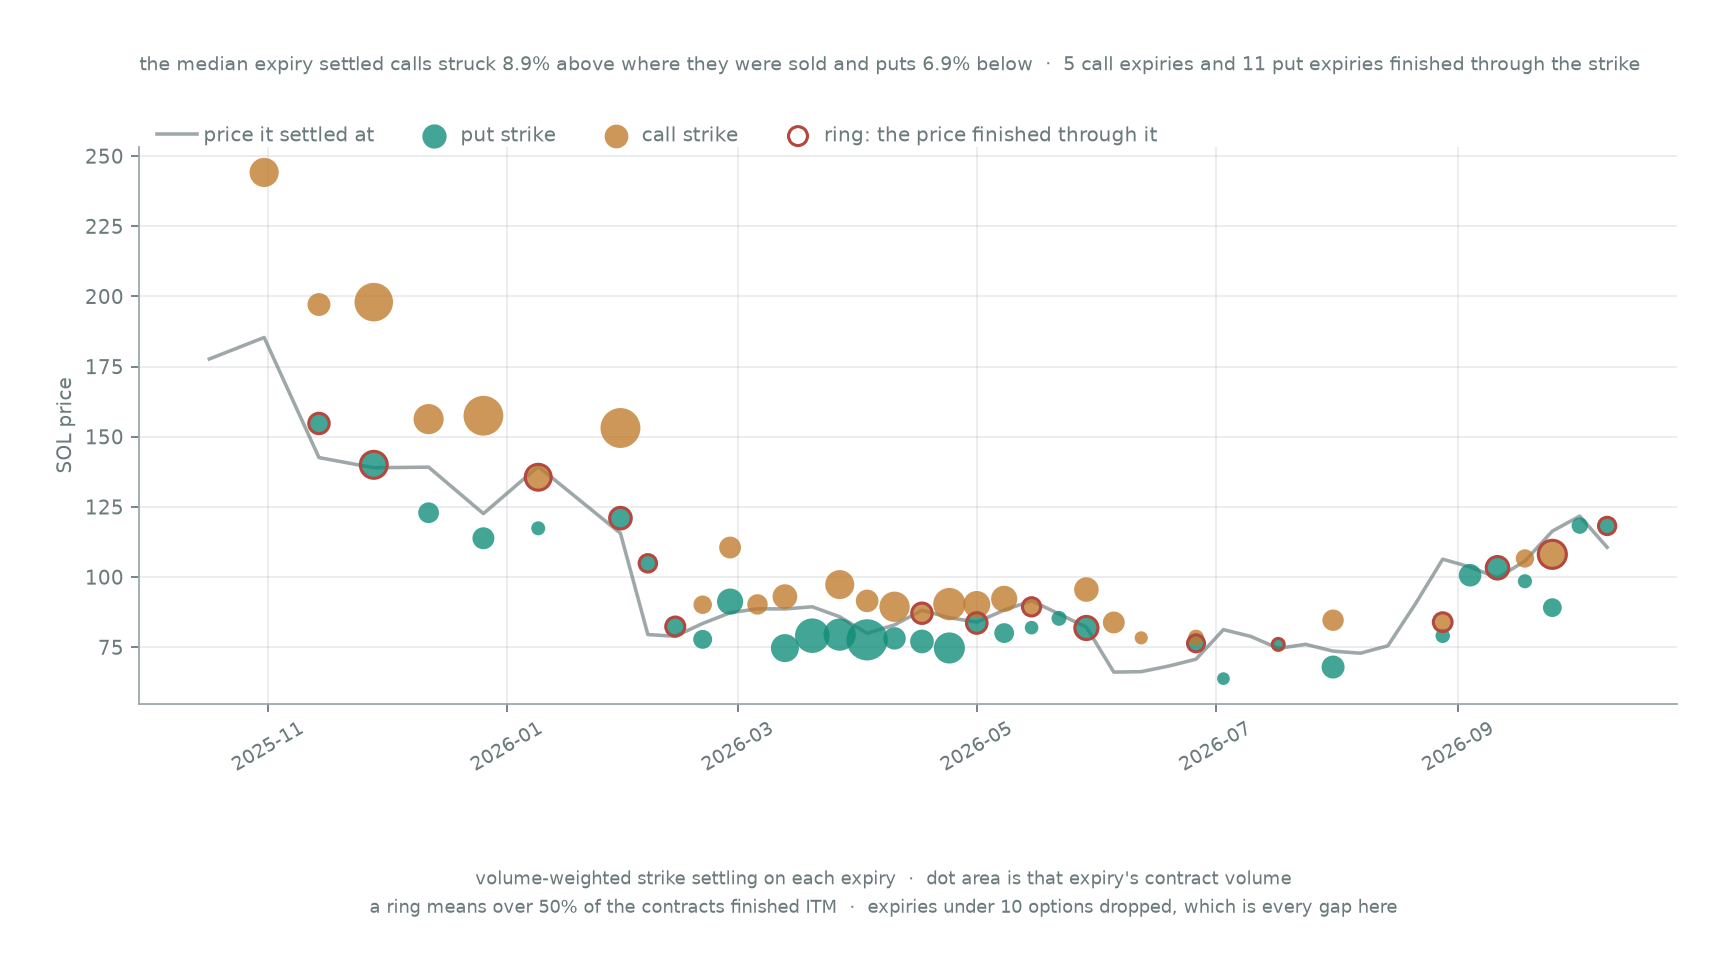

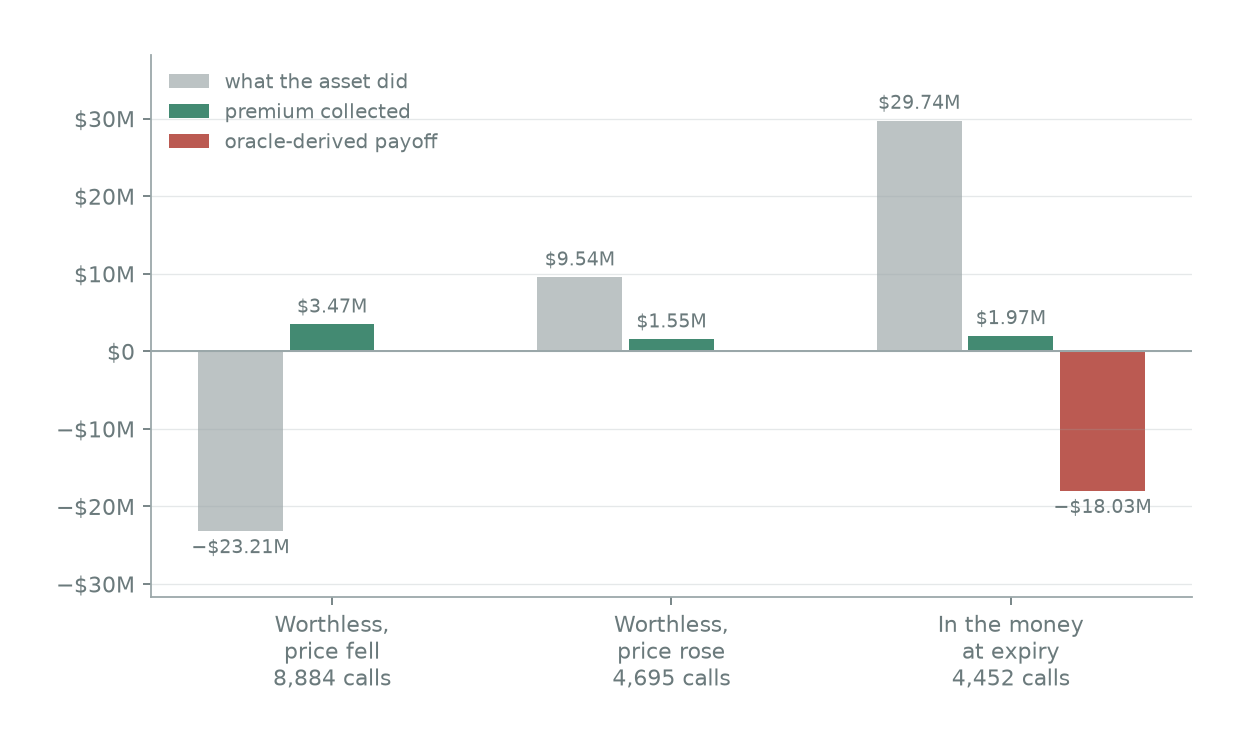

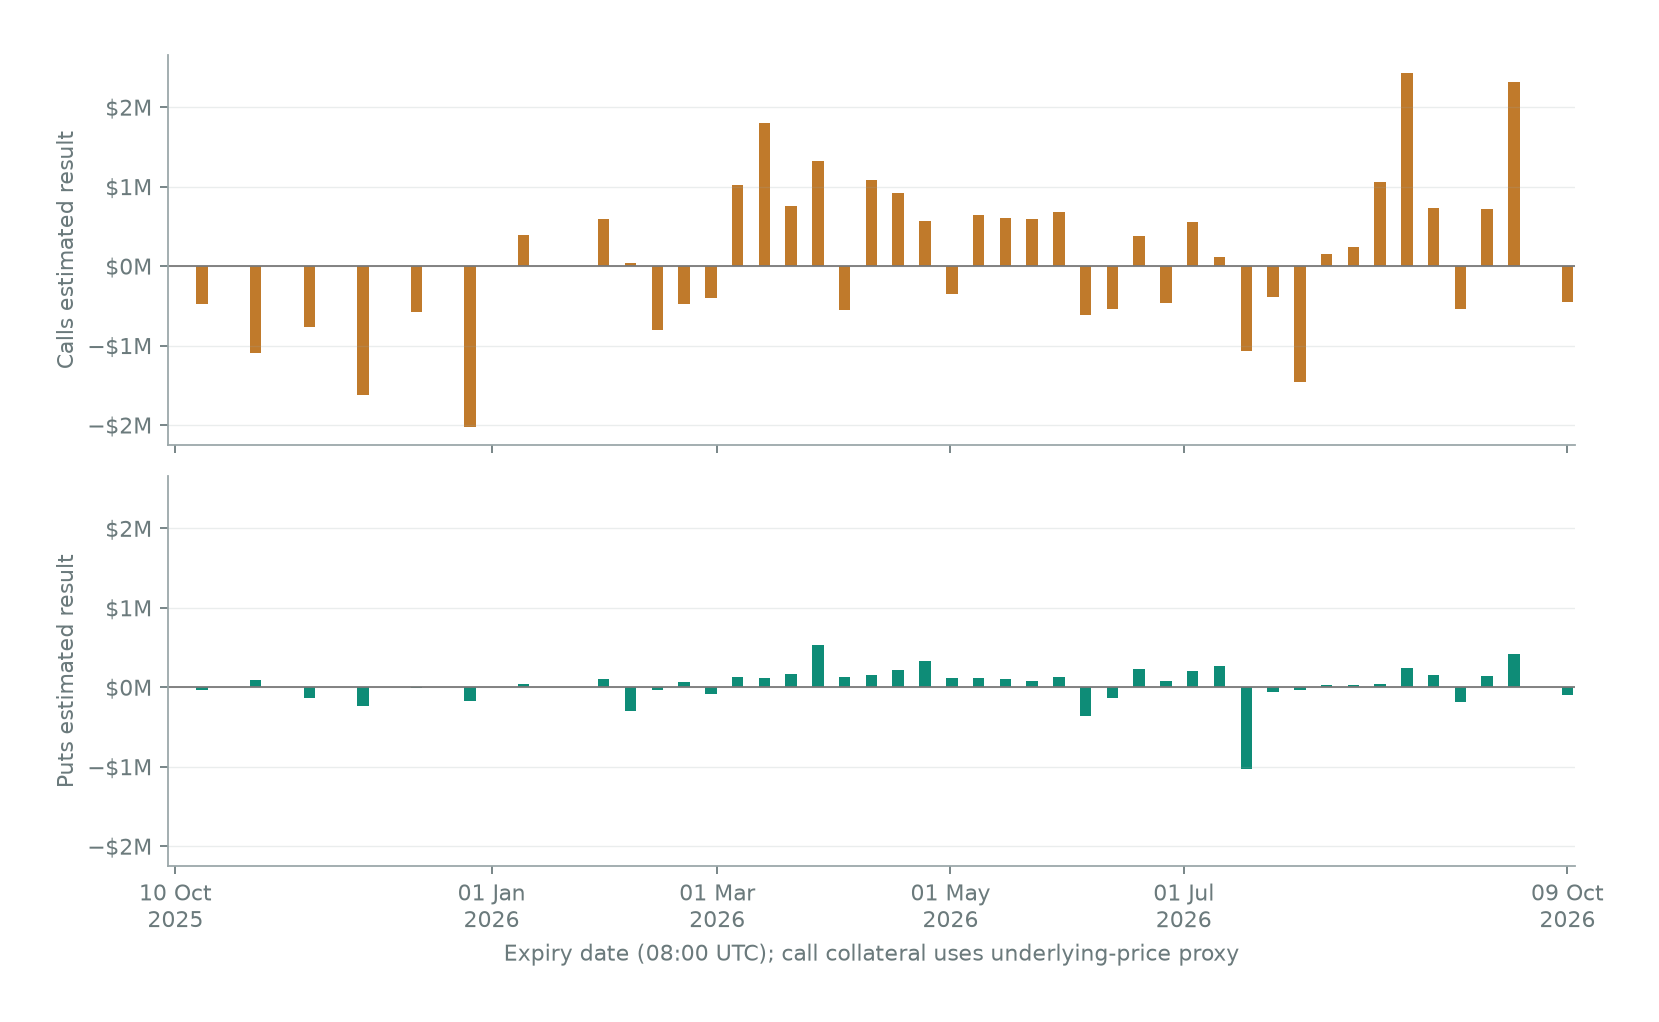

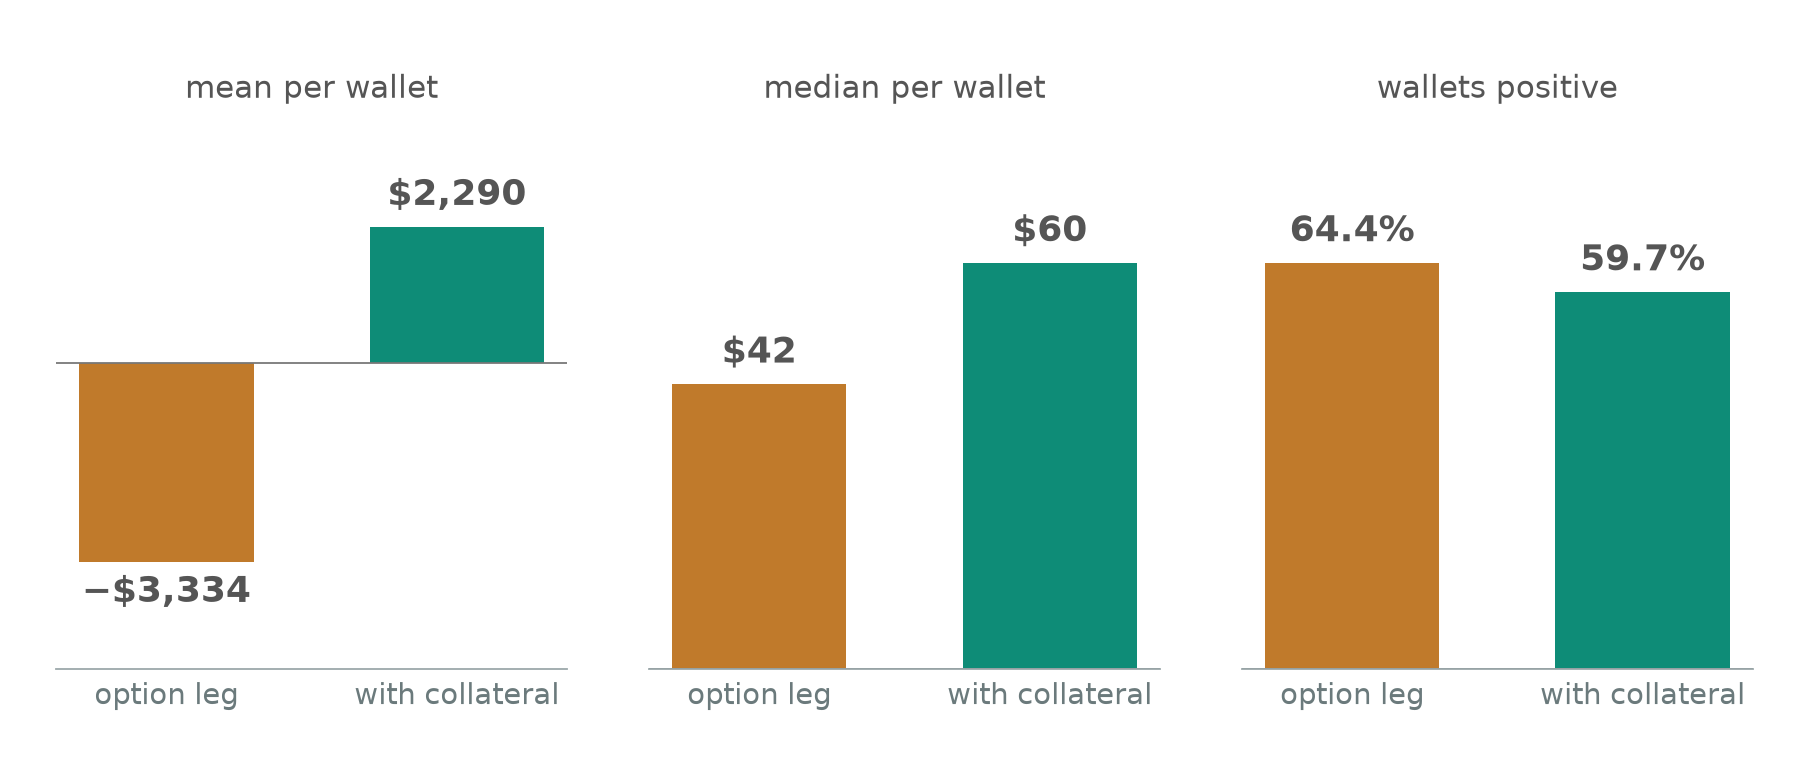

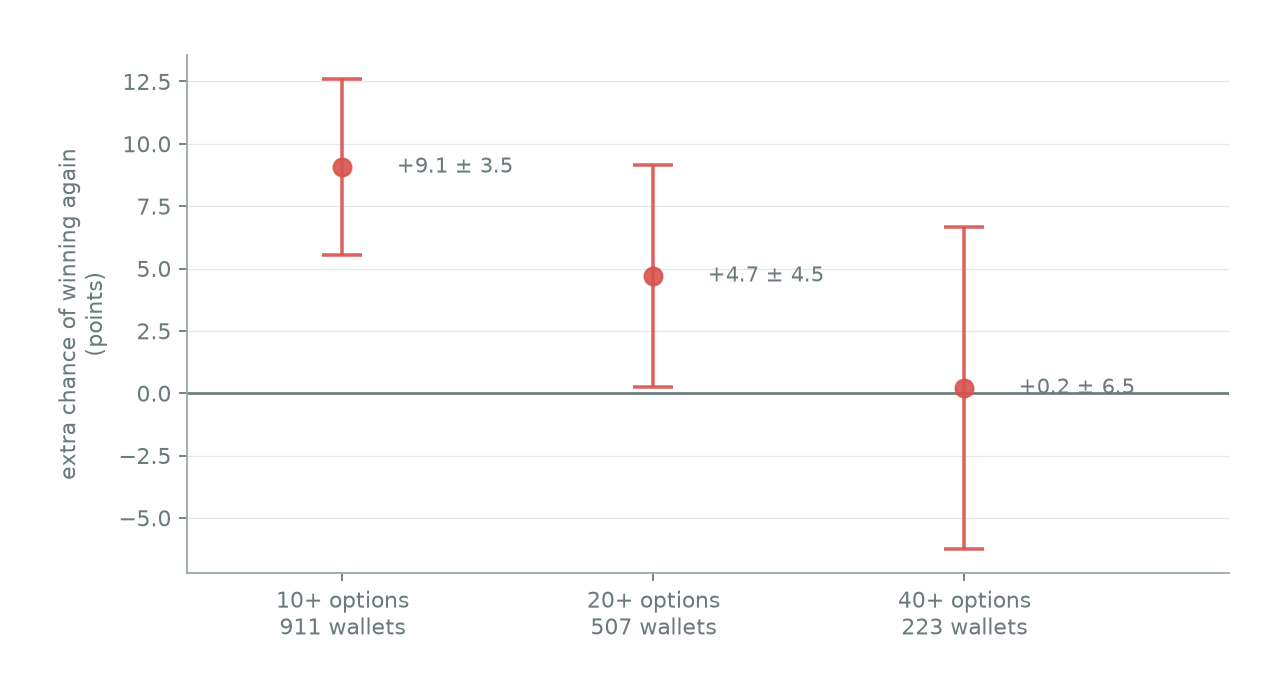

In [7]:
from option_intel import charts_rysk_year
import os
import matplotlib.pyplot as plt

os.environ["SOURCE_DATE_EPOCH"] = str(int(datetime.fromisoformat(config["asof"]).timestamp()))
plt.rcParams["svg.hashsalt"] = "rysk-year-" + config["asof"]
plt.rcParams.update(
    {
        "savefig.transparent": False,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
    }
)
from IPython.display import Image, display

for name, draw in charts_rysk_year.FIGURES.items():
    path = draw(rows, published, (BUNDLE / "charts") / f"{name}.png")
    draw(rows, published, (BUNDLE / "charts") / f"{name}.svg")
    display(Image(filename=str(path)))


## Interpretation
A wallet is an address, not a person. Results sum individual option lifetimes, so collateral reused across trades is counted in successive intervals. Gas, hedges, financing and outside positions are excluded.
Writing prices use cached Hyperliquid candles and, near the strike, pinned Binance minute observations where available. Expiry payoff uses only protocol oracle prices. The combined scenario values each collateral unit as one underlying unit; staking rates, PT discounts and wrapper basis are not measured. Token-specific collateral P&L and wallet-wide returns cannot be inferred from this scenario.